In [1]:
# подготовительный этап для всяких запусков

In [ ]:
from datetime import datetime
import os

# Создаём папку для результатов с датой
today = datetime.now().strftime("%Y-%m-%d")
results_dir = f"results/{today}"
os.makedirs(results_dir, exist_ok=True)

# Сохраняем туда
results_df.to_csv(f"{results_dir}/schools_analysis.csv")

In [2]:
# import pathlib
# import shutil
#
# cache_dir = pathlib.Path.home() / "AppData" / "Local" / "r5py"
# for f in cache_dir.glob("*.mapdb*"):
#     f.unlink()
#     print(f"Удалён: {f}")
#
# print("Кэш очищен!")

Удалён: C:\Users\olesy\AppData\Local\r5py\02103f44b82b05ee16b0e37cbac34423ce20d8f3135a698a46b1135f4d1fac0c.mapdb
Удалён: C:\Users\olesy\AppData\Local\r5py\02103f44b82b05ee16b0e37cbac34423ce20d8f3135a698a46b1135f4d1fac0c.mapdb.p
Удалён: C:\Users\olesy\AppData\Local\r5py\9f511c40c2e3e4d005c6f98469cadf1d16db839b11b7c948d6cd154a1fe1ef9d.mapdb
Удалён: C:\Users\olesy\AppData\Local\r5py\9f511c40c2e3e4d005c6f98469cadf1d16db839b11b7c948d6cd154a1fe1ef9d.mapdb.p
Удалён: C:\Users\olesy\AppData\Local\r5py\a9ff9caa0529f71060b517e933431551af3dca9f6e3448493758efe94b28157d.mapdb
Удалён: C:\Users\olesy\AppData\Local\r5py\a9ff9caa0529f71060b517e933431551af3dca9f6e3448493758efe94b28157d.mapdb.p
Удалён: C:\Users\olesy\AppData\Local\r5py\b086aba4439dc5b85240df79d723b01bcfdc43689df2ec1eca302a75923195b1.mapdb
Удалён: C:\Users\olesy\AppData\Local\r5py\b086aba4439dc5b85240df79d723b01bcfdc43689df2ec1eca302a75923195b1.mapdb.p
Кэш очищен!


# Библиотеки

In [4]:
jdk_home = r"C:\Users\olesy\PycharmProjects\JupyterProject2\.venv\Lib\site-packages\jdk4py\java-runtime"

In [5]:
import os
os.environ["JAVA_HOME"] = r"C:\Program Files\Eclipse Adoptium\jdk-21.0.11.10-hotspot"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

In [6]:
pip install osmium

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import r5py
import osmium
import os
print(r5py.__version__)

1.1.3


In [8]:
# network = r5py.TransportNetwork(
#     osm_pbf=r"C:\Users\olesy\PycharmProjects\JupyterProject2\data\SPB.osm.pbf",  # укажи полный путь если файл не в папке проекта
#     gtfs=[r"C:\Users\olesy\PycharmProjects\JupyterProject2\data\feed.zip"]                        # аналогично
# )
#
# print("Сеть построена!")

In [9]:
# import java.io
#
# output_path = java.io.File(r"C:\Users\olesy\PycharmProjects\JupyterProject2\data\spb_network.dat")
# com.conveyal.r5.kryo.KryoNetworkSerializer.write(network._transport_network, output_path)
# print("Сохранено!")

In [10]:
import jpype
import jpype.imports
import r5py
import java.io
from com.conveyal.r5.kryo import KryoNetworkSerializer
# Загрузка сети из файла
input_path = java.io.File(r"C:\Users\olesy\PycharmProjects\JupyterProject2\data\spb_network.dat")
transport_network_java = KryoNetworkSerializer.read(input_path)

# Оборачиваем в r5py объект
network = r5py.TransportNetwork.__new__(r5py.TransportNetwork)
network._transport_network = transport_network_java

print("Сеть успешно загружена!")
print(f"Тип: {type(network)}")

Сеть успешно загружена!
Тип: <class 'r5py.r5.transport_network.TransportNetwork'>


In [11]:
import geopandas as gpd

In [12]:
blocks = gpd.read_file(r'C:\Users\olesy\PycharmProjects\JupyterProject2\data\blocks.geojson')
schools = gpd.read_file(r'C:\Users\olesy\PycharmProjects\JupyterProject2\data\Школа, Санкт-Петербург.geojson')
OOSA = gpd.read_file(r'C:\Users\olesy\PycharmProjects\JupyterProject2\data\Дом детского творчества, Санкт-Петербург.geojson')
districts = gpd.read_file(r'C:\Users\olesy\PycharmProjects\JupyterProject2\data\Санкт-Петербург (1).geojson')

In [13]:
blocks = blocks.to_crs(epsg=4326)

In [14]:
print(blocks.crs)
print(schools.crs)
print(OOSA.crs)
print(districts.crs)

EPSG:4326
EPSG:4326
EPSG:4326
EPSG:4326


In [15]:
print(blocks.columns.tolist())

['site_area', 'residential', 'business', 'recreation', 'industrial', 'transport', 'special', 'agriculture', 'land_use', 'share', 'footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'population', 'count_buildings', 'capacity_school', 'count_school', 'capacity_kindergarten', 'count_kindergarten', 'capacity_hospital', 'count_hospital', 'capacity_polyclinic', 'count_polyclinic', 'capacity_pitch', 'count_pitch', 'capacity_swimming_pool', 'count_swimming_pool', 'capacity_theatre', 'count_theatre', 'capacity_museum', 'count_museum', 'capacity_cinema', 'count_cinema', 'capacity_mall', 'count_mall', 'capacity_convenience', 'count_convenience', 'capacity_supermarket', 'count_supermarket', 'capacity_cemetery', 'count_cemetery', 'capacity_religion', 'count_religion', 'capacity_market', 'count_market', 'capacity_university', 'count_university', 'capacity_playground', 'count_playground', 'capacity_pharmacy', 'count_pharmacy', 'capacity_fuel', 'count_fuel', 'capacity_beach', 'coun

# Генерация

In [27]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point

# Перепроецируем блоки для генерации точек
blocks_4326 = blocks.to_crs(epsg=4326)

# Генерируем случайные точки домов внутри кварталов
# взвешено по населению — чем больше людей, тем больше точек
def random_points_in_polygon(polygon, n=1):
    points = []
    minx, miny, maxx, maxy = polygon.bounds
    while len(points) < n:
        pnt = Point(np.random.uniform(minx, maxx), np.random.uniform(miny, maxy))
        if polygon.contains(pnt):
            points.append(pnt)
    return points

np.random.seed(42)
N_HOMES = 1  # количество случайных домов

# Веса по населению
weights = blocks_4326['population'].fillna(0)
weights = weights / weights.sum()

# Выбираем кварталы с вероятностью пропорциональной населению
chosen_blocks = blocks_4326.sample(n=N_HOMES, weights=weights, replace=True)

# Генерируем по одной точке в каждом выбранном квартале
home_points = []
for idx, row in chosen_blocks.iterrows():
    pt = random_points_in_polygon(row.geometry, n=1)[0]
    home_points.append({'block_id': idx, 'geometry': pt})

homes_gdf = gpd.GeoDataFrame(home_points, crs='EPSG:4326')
homes_gdf['id'] = range(len(homes_gdf))

print(f"Сгенерировано {len(homes_gdf)} точек домов")
print(homes_gdf.head(3))

Сгенерировано 1 точек домов
   block_id                   geometry  id
0      5037  POINT (30.21139 59.83901)   0


In [28]:
# # точка
# Сгенерировано 1 точек домов
#    block_id                   geometry  id
# 0      5037  POINT (30.21139 59.83901)   0


# Фиксируем точки — не меняем при перезапуске
HOME_POINT = Point(30.21139, 59.83901)  # подставь свои координаты
WORK_POINT = Point(30.315, 59.934)     # подставь свои координаты

In [35]:
# Подготовим школы
schools['id'] = range(len(schools))
print(f"Школ всего: {len(schools)}")
print(schools.head(3))
print(schools.columns.tolist())

Школ всего: 1646
                       Название  Вместимость Вместимость реальная/прогнозная  \
0                     Школа №31         1220                        реальная   
1  Академическая гимназия СПбГУ          360                        реальная   
2            ГБОУ гимназия № 32          139                        реальная   

                 Территория Тип сервиса  \
0  округ Остров Декабристов       Школа   
1  округ Остров Декабристов       Школа   
2        Васильевский округ       Школа   

                                            geometry  id  
0  MULTIPOLYGON (((30.2178 59.95746, 30.21803 59....   0  
1  MULTIPOLYGON (((30.23489 59.95235, 30.23516 59...   1  
2  MULTIPOLYGON (((30.2824 59.94596, 30.28257 59....   2  
['Название', 'Вместимость', 'Вместимость реальная/прогнозная', 'Территория', 'Тип сервиса', 'geometry', 'id']


In [36]:
schools_points = schools.copy()
schools_points['geometry'] = schools.to_crs(epsg=32636).geometry.centroid
schools_points = schools_points.to_crs(epsg=4326)
print(schools_points.head(3))

                       Название  Вместимость Вместимость реальная/прогнозная  \
0                     Школа №31         1220                        реальная   
1  Академическая гимназия СПбГУ          360                        реальная   
2            ГБОУ гимназия № 32          139                        реальная   

                 Территория Тип сервиса                   geometry  id  
0  округ Остров Декабристов       Школа  POINT (30.21848 59.95758)   0  
1  округ Остров Декабристов       Школа  POINT (30.23515 59.95209)   1  
2        Васильевский округ       Школа  POINT (30.28277 59.94581)   2  


In [17]:
calendar = pd.read_csv(r'C:\Users\olesy\PycharmProjects\JupyterProject2\data\calendar.txt')

In [18]:
weekday = calendar[calendar['tuesday'] == 1].iloc[0]
print(weekday['start_date'], weekday['end_date'])

20191230 20260318


In [14]:
from datetime import datetime, timedelta
import threading
import time

result = [None]
error = [None]

def run():
    try:
        result[0] = r5py.TravelTimeMatrix(
            network,
            origins=homes_gdf,
            destinations=schools_points,
            departure=datetime(2026, 2, 23, 7, 0),
            transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
            max_time=timedelta(hours=0.5)
        )
    except Exception as e:
        error[0] = e

thread = threading.Thread(target=run)
thread.start()

i = 0
chars = "⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏"
while thread.is_alive():
    print(f"\r{chars[i % len(chars)]} Считаем маршруты...", end="", flush=True)
    i += 1
    time.sleep(0.1)

thread.join()

if error[0]:
    raise error[0]

travel_times = result[0]
print(f"\r✅ Готово! Маршрутов рассчитано: {len(travel_times)}")
print(travel_times.head(10))

✅ Готово! Маршрутов рассчитано: 1646
   from_id  to_id  travel_time
0        0      0          0.0
1        0      1          NaN
2        0      2          NaN
3        0      3          NaN
4        0      4          NaN
5        0      5          NaN
6        0      6          NaN
7        0      7          NaN
8        0      8          NaN
9        0      9          NaN


In [15]:
print(travel_times['travel_time'].value_counts())

travel_time
22.0    17
23.0    16
25.0    15
21.0    11
26.0    11
24.0    10
27.0    10
20.0     9
29.0     6
18.0     5
14.0     4
28.0     4
12.0     2
17.0     2
0.0      1
8.0      1
9.0      1
19.0     1
15.0     1
Name: count, dtype: int64


In [16]:
print(f"Всего строк: {len(travel_times)}")
print(f"NaN: {travel_times['travel_time'].isna().sum()}")
print(f"Не NaN: {travel_times['travel_time'].notna().sum()}")
print(f"\nСреднее время: {travel_times['travel_time'].mean():.1f} мин")
print(f"Макс время: {travel_times['travel_time'].max():.1f} мин")

Всего строк: 1646
NaN: 1519
Не NaN: 127

Среднее время: 22.6 мин
Макс время: 29.0 мин


In [37]:
import numpy as np
from shapely.geometry import Point

# Берём школы достижимые за 30 минут
reachable_schools = travel_times[travel_times['travel_time'].notna()].copy()
reachable_schools = reachable_schools.sort_values('travel_time')
# Берём все достижимые школы как origins
reachable_ids = reachable_schools['to_id'].tolist()
schools_origins = schools_points[schools_points['id'].isin(reachable_ids)].copy()

# Случайная точка работы
work_point = gpd.GeoDataFrame(
    [{'id': 0, 'geometry': Point(30.315, 59.934)}],
    crs='EPSG:4326'
)

# Одним вызовом считаем школа → работа для всех школ
t2_matrix = r5py.TravelTimeMatrix(
    network,
    origins=schools_origins,
    destinations=work_point,
    departure=datetime(2026, 2, 23, 8, 0),
    transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
    max_time=timedelta(hours=2)
)

# Объединяем с временем дом → школа
results_df = reachable_schools[['to_id', 'travel_time']].rename(
    columns={'to_id': 'school_id', 'travel_time': 't_home_school'}
)
results_df = results_df.merge(
    t2_matrix[['from_id', 'travel_time']].rename(
        columns={'from_id': 'school_id', 'travel_time': 't_school_work'}
    ),
    on='school_id'
)
results_df['t_total'] = results_df['t_home_school'] + 5 + results_df['t_school_work']

# Добавим названия школ
results_df = results_df.merge(
    schools_points[['id', 'Название']].rename(columns={'id': 'school_id'}),
    on='school_id'
)

print(results_df.sort_values('t_total'))

# 38 минут это занимает (127 ориджин х 1 дестинейшн- примерно 18 секунд на каждое

NameError: name 'travel_times' is not defined

In [20]:
results_df

,school_id,t_home_school,t_school_work,t_total,Название
0,0,0.0,0,5.0,Школа №31
1,469,8.0,62,75.0,Школа № 240
2,1174,9.0,61,75.0,Школа № 240
3,468,12.0,59,76.0,Школа №254
4,1143,12.0,60,77.0,Школа № 254
...,...,...,...,...,...
122,604,29.0,72,106.0,Гимназия №399
123,489,29.0,63,97.0,Школа №551
124,770,29.0,62,96.0,Школа № 551
125,944,29.0,72,106.0,Гимназия № 399


In [21]:
results_df.to_csv('1o_1d_127s_1_05.csv', index=False)

In [21]:
import pandas as pd

In [38]:
mrn_juniors = pd.read_csv(r'C:\Users\olesy\PycharmProjects\JupyterProject2\1o_1d_127s_1_05.csv')

In [39]:
mrn_juniors


,school_id,t_home_school,t_school_work,t_total,Название
0,0,0.0,0,5.0,Школа №31
1,469,8.0,62,75.0,Школа № 240
2,1174,9.0,61,75.0,Школа № 240
3,468,12.0,59,76.0,Школа №254
4,1143,12.0,60,77.0,Школа № 254
...,...,...,...,...,...
122,604,29.0,72,106.0,Гимназия №399
123,489,29.0,63,97.0,Школа №551
124,770,29.0,62,96.0,Школа № 551
125,944,29.0,72,106.0,Гимназия № 399


In [40]:
# Дубли по названию
print(schools_points[schools_points['Название'] == 'Школа №254'])

       Название  Вместимость Вместимость реальная/прогнозная     Территория  \
468  Школа №254          888                        реальная  округ Ульянка   

    Тип сервиса                   geometry   id  
468       Школа  POINT (30.20423 59.83561)  468  


In [41]:
schools_points

,Название,Вместимость,Вместимость реальная/прогнозная,Территория,Тип сервиса,geometry,id
0,Школа №31,1220,реальная,округ Остров Декабристов,Школа,POINT (30.21848 59.95758),0
1,Академическая гимназия СПбГУ,360,реальная,округ Остров Декабристов,Школа,POINT (30.23515 59.95209),1
2,ГБОУ гимназия № 32,139,реальная,Васильевский округ,Школа,POINT (30.28277 59.94581),2
3,Школа №21,493,реальная,округ № 7,Школа,POINT (30.28423 59.94066),3
4,ГБОУ школа №220,448,реальная,округ Пискаревка,Школа,POINT (30.38302 59.9872),4
...,...,...,...,...,...,...,...
1641,Школа № 71,800,прогнозная,округ Академическое,Школа,POINT (30.39297 60.01692),1641
1642,Школа № 331,800,прогнозная,округ Ивановский,Школа,POINT (30.43917 59.87873),1642
1643,Дошкольное отделение школы № 582,800,прогнозная,округ Озеро Долгое,Школа,POINT (30.24038 60.01306),1643
1644,Школа № 98,800,прогнозная,округ Академическое,Школа,POINT (30.39907 60.02036),1644


In [42]:
print(schools_points[schools_points['id'] == 1143])

         Название  Вместимость Вместимость реальная/прогнозная     Территория  \
1143  Школа № 254          800                      прогнозная  округ Ульянка   

     Тип сервиса                   geometry    id  
1143       Школа  POINT (30.20469 59.83559)  1143  


In [43]:
schools_points = schools_points[
    schools_points['Вместимость реальная/прогнозная'] == 'реальная'
].copy()
print(f"Реальных школ: {len(schools_points)}")

Реальных школ: 734


In [44]:
mrn_juniors = mrn_juniors[
    mrn_juniors['school_id'].isin(
        schools_points[schools_points['Вместимость реальная/прогнозная'] == 'реальная']['id']
    )
].copy()
print(mrn_juniors.sort_values('t_total'))

     school_id  t_home_school  t_school_work  t_total       Название
0            0            0.0              0      5.0      Школа №31
1          469            8.0             62     75.0    Школа № 240
3          468           12.0             59     76.0     Школа №254
6          473           14.0             57     76.0     Школа №392
18         491           20.0             51     76.0     Школа №504
..         ...            ...            ...      ...            ...
105        597           26.0             68     99.0  Гимназия №505
111        603           27.0             67     99.0     Школа №131
108        602           27.0             69    101.0    Школа № 217
107        600           27.0             71    103.0     Школа №291
122        604           29.0             72    106.0  Гимназия №399

[63 rows x 5 columns]


In [45]:
mrn_juniors['home'] = HOME_POINT
mrn_juniors['work'] = WORK_POINT

In [51]:
pip install networkx

  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pickle

with open(r"C:\Users\olesy\PycharmProjects\JupyterProject2\data\graph_spb.pkl", 'rb') as f:
    G = pickle.load(f)

print(type(G))

<class 'networkx.classes.multidigraph.MultiDiGraph'>


In [3]:
import networkx as nx

print(f"Узлов: {G.number_of_nodes()}")
print(f"Рёбер: {G.number_of_edges()}")

# Смотрим атрибуты одного ребра
edge = list(G.edges(data=True))[0]
print("\nПример ребра:")
print(edge[2])

Узлов: 19034
Рёбер: 42034

Пример ребра:
{'osmid': 33997807, 'highway': 'primary_link', 'lanes': '2', 'maxspeed': 'RU:urban', 'oneway': False, 'reversed': False, 'length': np.float64(25.051385322981), 'speed_kph': 60.0, 'travel_time': 1.50308311937886}


In [18]:
pip install osmnx

  Using cached osmnx-2.1.0-py3-none-any.whl.metadata (4.7 kB)
Using cached osmnx-2.1.0-py3-none-any.whl (104 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import osmnx as ox

# Находим ближайшие узлы к точкам
home_node = ox.distance.nearest_nodes(G, HOME_POINT.x, HOME_POINT.y)
work_node = ox.distance.nearest_nodes(G, WORK_POINT.x, WORK_POINT.y)

# Для каждой школы считаем дом→школа→работа на авто
car_results = []

for _, row in mrn_juniors.iterrows():
    school_geom = schools_points[schools_points['id'] == row['school_id']].iloc[0]['geometry']
    school_node = ox.distance.nearest_nodes(G, school_geom.x, school_geom.y)

    try:
        t1 = nx.shortest_path_length(G, home_node, school_node, weight='travel_time')
        t2 = nx.shortest_path_length(G, school_node, work_node, weight='travel_time')
        total = (t1 + 5*60 + t2) / 60  # переводим секунды в минуты
    except nx.NetworkXNoPath:
        t1, t2, total = None, None, None

    car_results.append({
        'school_id': row['school_id'],
        't_home_school_car': t1/60 if t1 else None,
        't_school_work_car': t2/60 if t2 else None,
        't_total_car': total
    })

car_df = pd.DataFrame(car_results)
mrn_juniors = mrn_juniors.merge(car_df, on='school_id')
print(mrn_juniors[['Название', 't_total', 't_total_car']].sort_values('t_total'))

         Название  t_total  t_total_car
0       Школа №31      5.0    29.370559
1     Школа № 240     75.0    20.812873
2      Школа №254     76.0    21.066369
3      Школа №392     76.0    19.657451
8      Школа №504     76.0    19.657451
..            ...      ...          ...
52  Гимназия №505     99.0    24.833387
56     Школа №131     99.0    25.498961
55    Школа № 217    101.0    24.212317
54     Школа №291    103.0    25.498961
61  Гимназия №399    106.0    25.092777

[63 rows x 3 columns]


In [48]:
print(mrn_juniors[['Название', 't_home_school', 't_school_work', 't_total', 't_total_car']].sort_values('t_total'))
print(f"\nСреднее ОТ: {mrn_juniors['t_total'].mean():.1f} мин")
print(f"Среднее авто: {mrn_juniors['t_total_car'].mean():.1f} мин")
print(f"Среднее соотношение ОТ/авто: {(mrn_juniors['t_total'] / mrn_juniors['t_total_car']).mean():.2f}")

         Название  t_home_school  t_school_work  t_total  t_total_car
0       Школа №31            0.0              0      5.0    29.370559
1     Школа № 240            8.0             62     75.0    20.812873
2      Школа №254           12.0             59     76.0    21.066369
3      Школа №392           14.0             57     76.0    19.657451
8      Школа №504           20.0             51     76.0    19.657451
..            ...            ...            ...      ...          ...
52  Гимназия №505           26.0             68     99.0    24.833387
56     Школа №131           27.0             67     99.0    25.498961
55    Школа № 217           27.0             69    101.0    24.212317
54     Школа №291           27.0             71    103.0    25.498961
61  Гимназия №399           29.0             72    106.0    25.092777

[63 rows x 5 columns]

Среднее ОТ: 86.2 мин
Среднее авто: 21.6 мин
Среднее соотношение ОТ/авто: 4.02


In [52]:
mrn_juniors['ratio_car_to_pt'] = mrn_juniors['t_total'] / mrn_juniors['t_total_car']
print(mrn_juniors[['Название', 't_total', 't_total_car', 'ratio_car_to_pt']].sort_values('ratio_car_to_pt'))

            Название  t_total  t_total_car  ratio_car_to_pt
0          Школа №31      5.0    29.370559         0.170239
1        Школа № 240     75.0    20.812873         3.603539
2         Школа №254     76.0    21.066369         3.607646
51  ГБОУ Лицей № 395     97.0    26.633569         3.642020
30        Школа №264     79.0    21.497955         3.674768
..               ...      ...          ...              ...
23        Школа №223     91.0    20.588867         4.419864
60        Школа №546     97.0    21.895540         4.430126
15        Школа №377     81.0    18.283669         4.430183
48        Лицей №590     90.0    20.193649         4.456847
29        Школа №251     96.0    21.104275         4.548841

[63 rows x 4 columns]


In [54]:
pip install matplotlib

  Using cached matplotlib-3.10.9-cp314-cp314-win_amd64.whl.metadata (52 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.62.1-cp314-cp314-win_amd64.whl.metadata (119 kB)
  Using cached kiwisolver-1.5.0-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.2.0-cp314-cp314-win_amd64.whl.metadata (9.0 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 1.8 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.3 MB 1.7 MB/s eta 0:00:05
   ------ --------------------------------- 1.3/8.3 MB 1.8 MB/s eta 0:00:04
   ------- -------------------------------- 1.6/8.3 MB 1.6 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.3 MB 1.6 MB/s eta 0:00:04
   ----------- ---------------------------


[notice] A new release of pip is available: 25.1.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [72]:
mrn_juniors_sorted = mrn_juniors_sorted[mrn_juniors_sorted['school_id'] != 0].copy()

In [73]:
mrn_juniors_sorted

,school_id,t_home_school,t_school_work,t_total,Название,home,work,t_home_school_car,t_school_work_car,t_total_car,ratio_car_to_pt
1,469,8.0,62,75.0,Школа № 240,POINT (30.21139 59.83901),POINT (30.315 59.934),1.573140,14.239733,20.812873,3.603539
2,468,12.0,59,76.0,Школа №254,POINT (30.21139 59.83901),POINT (30.315 59.934),1.569722,14.496647,21.066369,3.607646
51,593,26.0,66,97.0,ГБОУ Лицей № 395,POINT (30.21139 59.83901),POINT (30.315 59.934),4.771609,16.861960,26.633569,3.642020
30,483,23.0,51,79.0,Школа №264,POINT (30.21139 59.83901),POINT (30.315 59.934),5.234082,11.263873,21.497955,3.674768
47,595,25.0,68,98.0,Лицей №395,POINT (30.21139 59.83901),POINT (30.315 59.934),5.153693,16.210470,26.364163,3.717167
...,...,...,...,...,...,...,...,...,...,...,...
23,470,22.0,64,91.0,Школа №223,POINT (30.21139 59.83901),POINT (30.315 59.934),1.261375,14.327492,20.588867,4.419864
60,615,29.0,63,97.0,Школа №546,POINT (30.21139 59.83901),POINT (30.315 59.934),4.407783,12.487757,21.895540,4.430126
15,480,21.0,55,81.0,Школа №377,POINT (30.21139 59.83901),POINT (30.315 59.934),2.605649,10.678020,18.283669,4.430183
48,619,25.0,60,90.0,Лицей №590,POINT (30.21139 59.83901),POINT (30.315 59.934),3.366987,11.826662,20.193649,4.456847


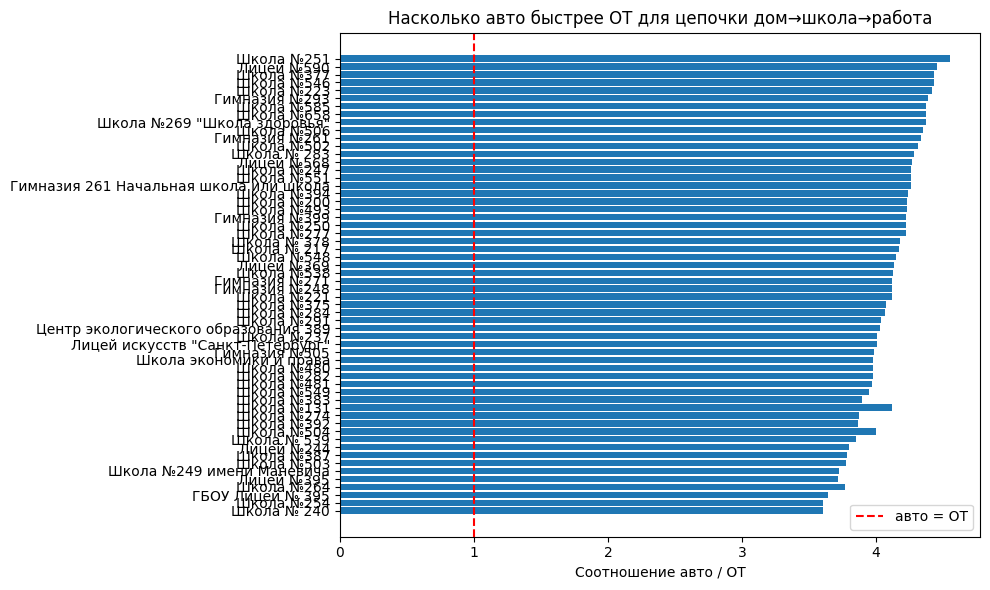

In [74]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

mrn_juniors_sorted = mrn_juniors_sorted.sort_values('ratio_car_to_pt')

ax.barh(mrn_juniors_sorted['Название'], mrn_juniors_sorted['ratio_car_to_pt'])
ax.axvline(x=1, color='red', linestyle='--', label='авто = ОТ')
ax.set_xlabel('Соотношение авто / ОТ')
ax.set_title('Насколько авто быстрее ОТ для цепочки дом→школа→работа')
ax.legend()

plt.tight_layout()
plt.show()

In [82]:
print(mrn_juniors_sorted['ratio_car_to_pt'].describe())

count    62.000000
mean      4.086615
std       0.236078
min       3.603539
25%       3.910963
50%       4.120079
75%       4.259318
max       4.548841
Name: ratio_car_to_pt, dtype: float64


In [80]:
mrn_juniors_sorted['ratio_centered'] = mrn_juniors_sorted['ratio_car_to_pt'] - mrn_juniors_sorted['ratio_car_to_pt'].mean()

In [81]:
print(mrn_juniors_sorted['ratio_centered'].describe())

count    6.200000e+01
mean     2.220446e-16
std      2.360776e-01
min     -4.830760e-01
25%     -1.756519e-01
50%      3.346361e-02
75%      1.727032e-01
max      4.622265e-01
Name: ratio_centered, dtype: float64
